In [2]:
!pip install -q -U ultralytics roboflow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 1.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 14.3 MB/s eta 0:00:0000:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 381.4/381.4 kB 13.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 82.5 MB/s eta 0:00:00ta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.1/100.1 kB 5.5 MB/s eta 0:00:00


In [15]:

import os
import glob
import shutil
import cv2
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ultralytics
from ultralytics import YOLO
from roboflow import Roboflow

print(f"Ultralytics Version : {ultralytics.__version__}")
print(f"PyTorch Version     : {torch.__version__}")
print(f"CUDA Available      : {torch.cuda.is_available()} (GPU Count: {torch.cuda.device_count()})")
if torch.cuda.is_available():
    print(f"Active GPU          : {torch.cuda.get_device_name(0)}")

def find_kaggle_input(filename: str, default_path: str = "") -> str:
    """Mencari path file secara otomatis di dalam /kaggle/input agar tidak salah mount path."""
    if default_path and os.path.exists(default_path):
        return default_path
    matches = glob.glob(f"/kaggle/input/**/{filename}", recursive=True)
    if matches:
        return matches[0]
    raise FileNotFoundError(f"File '{filename}' tidak ditemukan di /kaggle/input! Pastikan sudah ditambahkan di panel Input.")

Ultralytics Version : 8.4.194
PyTorch Version     : 2.10.0+cu128
CUDA Available      : True (GPU Count: 2)
Active GPU          : Tesla T4


## Download Dataset Roboflow

In [ ]:
from kaggle_secrets import UserSecretsClient
from roboflow import Roboflow

user_secrets = UserSecretsClient()
roboflow_api_key = user_secrets.get_secret("api_key")

rf = Roboflow(api_key=roboflow_api_key)
project = rf.workspace("group-6-major-project").project("card-grader")
version = project.version(5)
dataset = version.download("yolo26")

# Simpan lokasi data.yaml agar otomatis terbaca di Cell Training & Evaluasi
DATA_YAML = f"{dataset.location}/data.yaml"
print(f"\nDataset siap! Lokasi YAML: {DATA_YAML}")

loading Roboflow workspace...
loading Roboflow project...

Dataset siap! Lokasi YAML: /kaggle/working/Card-Grader-5/data.yaml


## 2. Training Model V6 (Ultralytics YOLO26s)

Konfigurasi pelatihan dirancang khusus untuk menjaga ketajaman piksel cacat mikro (`Scratch` & `Edge Wear`):
- **Arsitektur & Optimizer:** `yolo26s.pt` (`imgsz=800`) dengan `optimizer="auto"` untuk mengaktifkan **MuSGD** dan **STAL** (*Small-Target-Aware Label Assignment*).
- **Loss Localization:** `box=10.0` dan `cls=0.5` agar koordinat kotak cacat tipis presisi.
- **Defect-Preserving Augmentation (Opsi A):**
  - `mosaic=0.25` & `close_mosaic=30`: 75% gambar dilatih dalam kondisi 1 kartu utuh resolusi penuh sejak awal, dan 30 epoch terakhir murni bebas kolase.
  - `scale=0.15` & `translate=0.05`: Mencegah sudut/tepi kartu (`Corner Wear` & `Edge Wear`) terpotong keluar kanvas serta mencegah `Scratch` menyusut ekstrem.
  - `mixup=0.0`, `cutmix=0.0`, `copy_paste=0.0`: Dimatikan total agar tidak memicu goresan/garis potongan palsu.

In [17]:
# [CODE CELL 2 (REVISI V6.1) — Skala Setara V5 + Boost Klasifikasi Defect Samar]
model_v6_train = YOLO("yolo26s.pt")

train_results = model_v6_train.train(
    data=DATA_YAML,
    epochs=150,
    patience=30,
    imgsz=800,
    batch=16,
    device=0,
    optimizer="auto",    # MuSGD bawaan YOLO26
    box=7.5,             # Turunkan dari 10.0 ke standar agar tidak menekan skor cls
    cls=1.2,             # Naikkan dari 0.5 -> 1.2 agar Scratch/Edge Wear samar tidak dianggap background
    mosaic=1.0,          # Samakan dengan V5 agar tahan variasi skala & margin 120px
    close_mosaic=20,     # Samakan dengan V5 (20 epoch terakhir full kartu utuh)
    scale=0.50,          # Samakan dengan V5 agar kartu ukuran 50%-100% frame tetap dikenali kuat
    translate=0.10,      # Samakan dengan V5
    mixup=0.0,           # Tetap mati (merusak kontras goresan)
    cutmix=0.0,          # Tetap mati (menciptakan garis potong palsu)
    copy_paste=0.0,
    degrees=5.0,         # Toleransi miring tipis (±5 derajat) pada foto asli
    fliplr=0.5,
    flipud=0.0,
    project="/kaggle/working/runs_card_condition",
    name="v6_1_yolo26s_800px_tuned",
    save=True,
    plots=True
)

PATH_V6 = "/kaggle/working/best-model-v6-1-card-condition.pt"
shutil.copy("/kaggle/working/runs_card_condition/v6_1_yolo26s_800px_tuned/weights/best.pt", PATH_V6)
model_v6 = YOLO(PATH_V6)
print(f"\n[✓] Model V6.1 selesai dilatih dan disimpan di: {PATH_V6}")

Ultralytics 8.4.194 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=20, cls=1.2, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/Card-Grader-5/data.yaml, degrees=5.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=150, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=800, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=v6_1_yolo26s_800px_tuned, nbs=64, nms=None, opse

`get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.


      2/150      7.57G      2.162      5.955    0.01376        110        800: 100% ━━━━━━━━━━━━ 82/82 2.8it/s 29.0s0.3ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 3.4it/s 1.2s0.5s
                   all        122        948      0.849      0.359      0.349      0.208

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
      3/150      7.64G      2.134      5.341     0.0136         63        800: 100% ━━━━━━━━━━━━ 82/82 2.8it/s 29.3s0.3ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 3.4it/s 1.2s0.5s
                   all        122        948      0.633      0.331      0.348       0.18

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
      4/150      7.57G      2.156      5.156    0.01416         78        800: 100% ━━━━━━━━━━━━ 82/82 2.9it/s 28.6s0.3ss
                 Class     Images  Insta

### Kurva Training

[*] Total Epoch Berjalan : 139 epoch
[✓] Peak mAP50 Terbaik   : 0.4233 (pada Epoch ke-70)



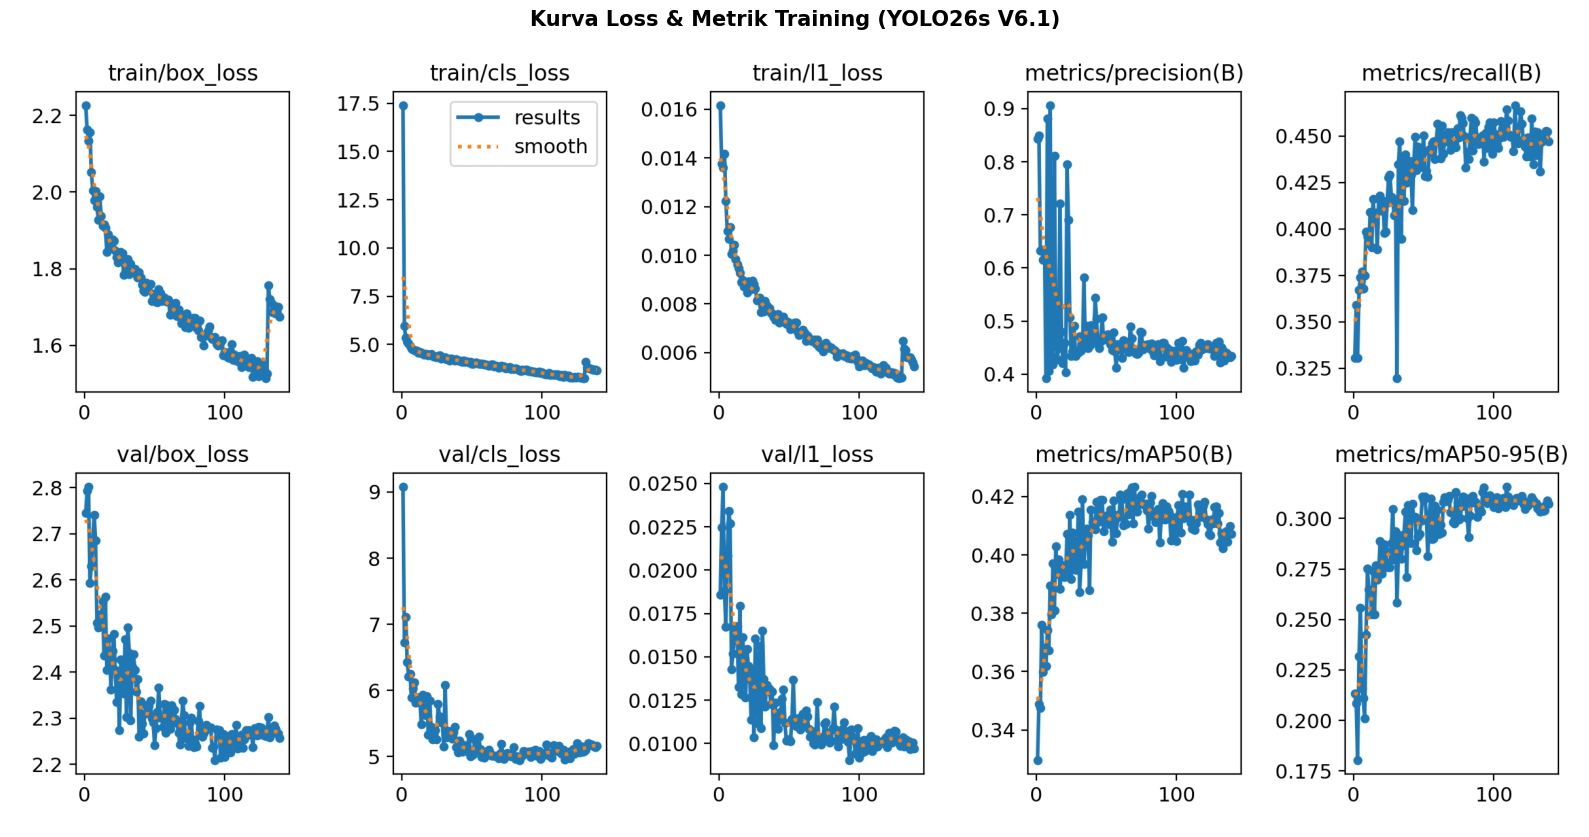

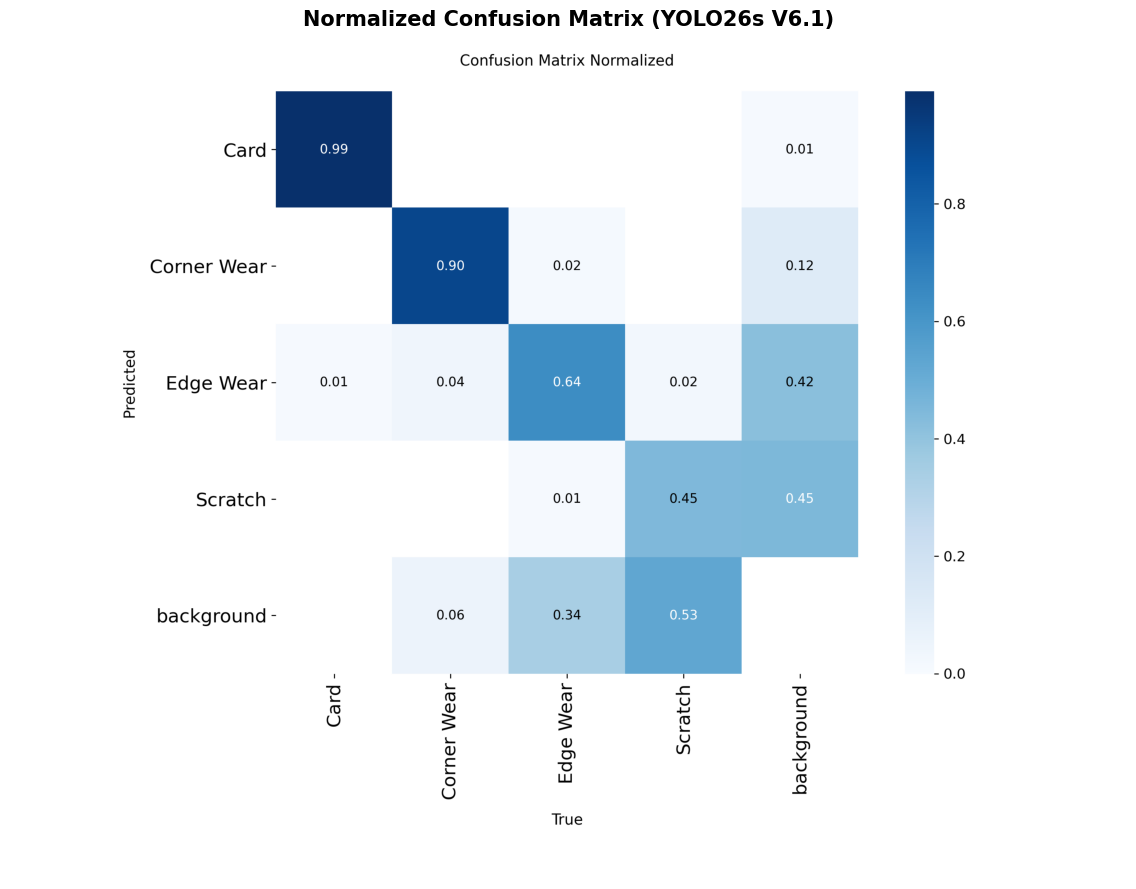

In [30]:
# [CODE CELL 2B — Visualisasi Kurva Training & Confusion Matrix YOLO26 (V6.1)]
RUN_DIR_V6 = "/kaggle/working/runs_card_condition/v6_1_yolo26s_800px_tuned"
csv_path = f"{RUN_DIR_V6}/results.csv"

if os.path.exists(csv_path):
    df_log = pd.read_csv(csv_path)
    df_log.columns = df_log.columns.str.strip()

    # Cari epoch terbaik berdasarkan mAP50
    map50_col = next((c for c in df_log.columns if "mAP50(" in c or c == "metrics/mAP50"), None)
    if map50_col:
        best_idx = df_log[map50_col].idxmax()
        best_ep = int(df_log.loc[best_idx, "epoch"])
        best_map50 = df_log.loc[best_idx, map50_col]
        print(f"[*] Total Epoch Berjalan : {len(df_log)} epoch")
        print(f"[✓] Peak mAP50 Terbaik   : {best_map50:.4f} (pada Epoch ke-{best_ep})\n")
else:
    print(f"[!] File results.csv tidak ditemukan di: {csv_path}")

# Tampilkan grafik kurva resmi Ultralytics (results.png) & Confusion Matrix
plot_files = [
    ("Kurva Loss & Metrik Training (YOLO26s V6.1)", f"{RUN_DIR_V6}/results.png"),
    ("Normalized Confusion Matrix (YOLO26s V6.1)", f"{RUN_DIR_V6}/confusion_matrix_normalized.png"),
]

for title_plot, p_file in plot_files:
    if os.path.exists(p_file):
        img_plot = cv2.cvtColor(cv2.imread(p_file), cv2.COLOR_BGR2RGB)
        plt.figure(figsize=(16, 9))
        plt.imshow(img_plot)
        plt.axis("off")
        plt.title(title_plot, fontsize=15, fontweight="bold", pad=12)
        plt.tight_layout()
        plt.show()
    else:
        print(f"[!] Gambar plot tidak ditemukan: {p_file}")

## Load Model V6 (YOLO26s — Pre-trained Checkpoint)

Memuat bobot hasil pelatihan **Model V6 (`YOLO26s`, `800px`)** langsung dari penyimpanan *Input* Kaggle sehingga evaluasi dapat dijalankan kembali setelah *session restart* tanpa perlu melatih ulang.

In [19]:
# # Cek apakah ada file v6-1, jika tidak fallback ke v6 biasa
# if os.path.exists("/kaggle/working/best-model-v6-1-card-condition.pt"):
#     PATH_V6 = "/kaggle/working/best-model-v6-1-card-condition.pt"
# elif os.path.exists("/kaggle/working/best-model-v6-card-condition.pt"):
#     PATH_V6 = "/kaggle/working/best-model-v6-card-condition.pt"
# else:
#     try:
#         PATH_V6 = find_kaggle_input("best-model-v6-1-card-condition.pt")
#     except FileNotFoundError:
#         PATH_V6 = find_kaggle_input("best-model-v6-card-condition.pt")

# print(f"[*] Memuat Model V6 dari: {PATH_V6}")
# model_v6 = YOLO(PATH_V6)

## 3. Load Model V3 (YOLOv8s-P2)

Memuat bobot hasil eksperimen **Model V3** yang menggunakan arsitektur kustom penambahan *P2 Detection Head* (`imgsz=640`).

In [31]:
PATH_V3 = find_kaggle_input(
    "best-model-v3-card-condition.pt",
    "/kaggle/input/models/tegarkusuma/card-condition-yolo8/other/default/1/best-model-v3-card-condition.pt"
)

print(f"[*] Memuat Model V3 dari: {PATH_V3}")
model_v3 = YOLO(PATH_V3)
print(f"[✓] Model V3 berhasil dimuat! Kelas: {model_v3.names}")

[*] Memuat Model V3 dari: /kaggle/input/models/tegarkusuma/card-condition-yolo8/other/default/1/best-model-v3-card-condition.pt
[✓] Model V3 berhasil dimuat! Kelas: {0: 'Card', 1: 'Corner Wear', 2: 'Edge Wear', 3: 'Scratch'}


## 4. Load Model V5 (YOLO11s)

Memuat bobot hasil eksperimen **Model V5** yang menggunakan arsitektur **YOLO11s** pada resolusi `imgsz=800`.

In [32]:
PATH_V5 = find_kaggle_input(
    "best-model-v5-card-condition.pt",
    "/kaggle/input/models/tegarkusuma/defect-card-pokemon/other/default/1/best-model-v5-card-condition.pt"
)

print(f"[*] Memuat Model V5 dari: {PATH_V5}")
model_v5 = YOLO(PATH_V5)
print(f"Model V5 berhasil dimuat! Kelas: {model_v5.names}")

[*] Memuat Model V5 dari: /kaggle/input/models/tegarkusuma/defect-card-pokemon/other/default/1/best-model-v5-card-condition.pt
Model V5 berhasil dimuat! Kelas: {0: 'Card', 1: 'Corner Wear', 2: 'Edge Wear', 3: 'Scratch'}


## 5. Hasil Perbandingan Evaluasi pada Dataset Test (`Precision`, `Recall`, `mAP50`)

Evaluasi dilakukan secara adil (*fair benchmark*) pada **`split='test'`** (data uji yang tidak pernah dilihat selama pelatihan) menggunakan metrik utama:
- **Precision (P):** Ketepatan prediksi model (seberapa minim *false positive*).
- **Recall (R):** Kemampuan model menemukan seluruh cacat asli (seberapa minim *false negative*).
- **mAP50:** Rata-rata presisi keseluruhan kelas pada ambang *IoU* 0.50.

In [33]:
print("[*] Mengevaluasi Model V3 (YOLOv8s-P2 @ 640px) pada Test Split...")
metrics_v3 = model_v3.val(data=DATA_YAML, split="test", imgsz=640, verbose=False)

print("[*] Mengevaluasi Model V5 (YOLO11s @ 800px) pada Test Split...")
metrics_v5 = model_v5.val(data=DATA_YAML, split="test", imgsz=800, verbose=False)

print("[*] Mengevaluasi Model V6.1 (YOLO26s @ 800px) pada Test Split...")
metrics_v6 = model_v6.val(data=DATA_YAML, split="test", imgsz=800, verbose=False)

# 1. Tabel Ringkasan Overall (Precision, Recall, mAP50)
summary_df = pd.DataFrame([
    {
        "Model": "Model V3 (YOLOv8s-P2 - 640px)",
        "Precision": round(float(metrics_v3.box.mp), 4),
        "Recall": round(float(metrics_v3.box.mr), 4),
        "mAP50": round(float(metrics_v3.box.map50), 4),
        "mAP50-95": round(float(metrics_v3.box.map), 4),
    },
    {
        "Model": "Model V5 (YOLO11s - 800px)",
        "Precision": round(float(metrics_v5.box.mp), 4),
        "Recall": round(float(metrics_v5.box.mr), 4),
        "mAP50": round(float(metrics_v5.box.map50), 4),
        "mAP50-95": round(float(metrics_v5.box.map), 4),
    },
    {
        "Model": "Model V6 (YOLO26s - 800px)",
        "Precision": round(float(metrics_v6.box.mp), 4),
        "Recall": round(float(metrics_v6.box.mr), 4),
        "mAP50": round(float(metrics_v6.box.map50), 4),
        "mAP50-95": round(float(metrics_v6.box.map), 4),
    }
])

print("\n" + "=" * 78)
print(f"{'RINGKASAN OVERALL TEST SPLIT: V3 vs V5 vs V6 (YOLO26)':^78}")
print("=" * 78)
print(summary_df.to_string(index=False))
print("=" * 78)

# 2. Tabel Rincian Per Kelas (Card, Corner Wear, Edge Wear, Scratch)
def cetak_detail_kelas(model, metrics, judul):
    print(f"\n  [ {judul} ]")
    print(f"  {'Class':<15} {'Precision (P)':>15} {'Recall (R)':>15} {'mAP50':>12}")
    print(f"  {'─' * 61}")
    for i, name in enumerate(model.names.values()):
        try:
            p = metrics.box.p[i]
            r = metrics.box.r[i]
            ap50 = metrics.box.ap50[i]
            print(f"  {name:<15} {p:>15.3f} {r:>15.3f} {ap50:>12.3f}")
        except IndexError:
            pass
    print(f"  {'─' * 61}")
    print(f"  {'OVERALL':<15} {metrics.box.mp:>15.3f} {metrics.box.mr:>15.3f} {metrics.box.map50:>12.3f}")

cetak_detail_kelas(model_v3, metrics_v3, "MODEL V3 (YOLOv8s-P2 - 640px)")
cetak_detail_kelas(model_v5, metrics_v5, "MODEL V5 (YOLO11s - 800px)")
cetak_detail_kelas(model_v6, metrics_v6, "MODEL V6 (YOLO26s - 800px)")

[*] Mengevaluasi Model V3 (YOLOv8s-P2 @ 640px) pada Test Split...
Ultralytics 8.4.194 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLOv8s-p2 summary (fused): 90 layers, 10,627,488 parameters, 0 gradients, 36.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 862.3±240.6 MB/s, size: 26.4 KB)
val: Scanning /kaggle/working/Card-Grader-5/test/labels.cache... 71 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 71/71 24.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 2.4it/s 2.1s0.6s
                   all         71        443      0.544       0.42       0.41      0.312
Speed: 2.9ms preprocess, 10.2ms inference, 0.3ms loss, 7.5ms postprocess per image
Results saved to /kaggle/working/runs/detect/val-7
[*] Mengevaluasi Model V5 (YOLO11s @ 800px) pada Test Split...
Ultralytics 8.4.194 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s summary (fused): 100 layers, 9,4

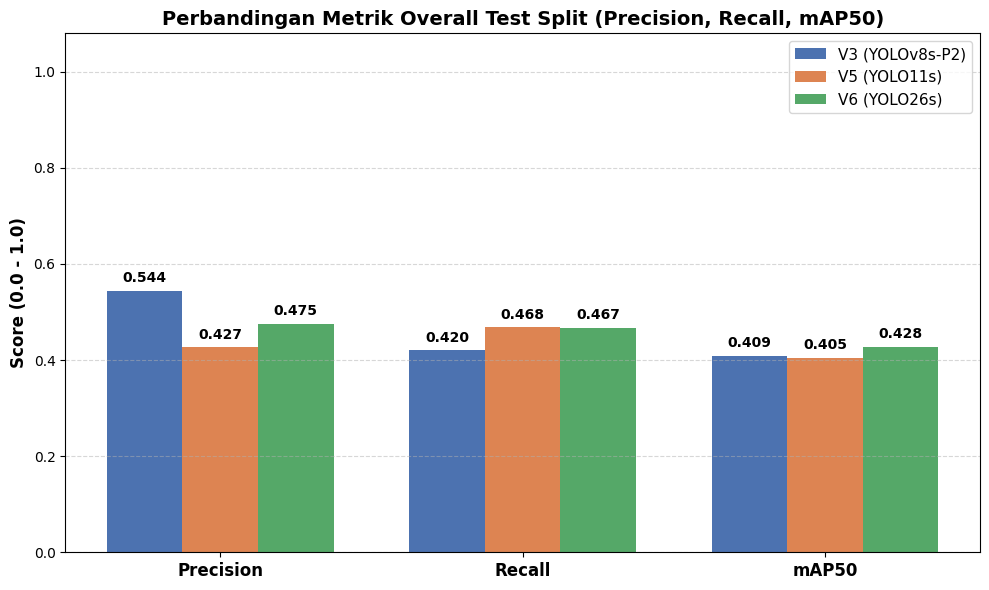

In [35]:
metrics_cols = ["Precision", "Recall", "mAP50"]
x = np.arange(len(metrics_cols))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 6))
bars_v3 = ax.bar(x - width, summary_df.loc[0, metrics_cols], width, label="V3 (YOLOv8s-P2)", color="#4C72B0")
bars_v5 = ax.bar(x,         summary_df.loc[1, metrics_cols], width, label="V5 (YOLO11s)",    color="#DD8452")
bars_v6 = ax.bar(x + width, summary_df.loc[2, metrics_cols], width, label="V6 (YOLO26s)",    color="#55A868")

ax.set_ylim(0, 1.08)
ax.set_ylabel("Score (0.0 - 1.0)", fontsize=12, fontweight="bold")
ax.set_title("Perbandingan Metrik Overall Test Split (Precision, Recall, mAP50)", fontsize=14, fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(metrics_cols, fontsize=12, fontweight="bold")
ax.legend(fontsize=11)
ax.grid(axis="y", linestyle="--", alpha=0.5)

for bars in [bars_v3, bars_v5, bars_v6]:
    for bar in bars:
        h = bar.get_height()
        ax.annotate(
            f"{h:.3f}",
            xy=(bar.get_x() + bar.get_width() / 2, h),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center", va="bottom", fontsize=10, fontweight="bold"
        )

plt.tight_layout()
plt.show()

## 6. Hasil Perbandingan Visual pada Foto Kartu Asli (Depan & Belakang)

Menguji ketajaman deteksi ketiga model secara berdampingan pada sampel foto kartu fisik nyata dari dataset `Defect-Card-Pokemon` (`defect-card-front.jpeg` dan `defect-card-back.jpeg`).


FOTO KARTU ASLI: TAMPAK DEPAN (FRONT) (defect-card-front.jpeg)

  [Model V3 (YOLOv8s-P2)]
    - Card           :  77.1%

  [Model V5 (YOLO11s)]
    - Card           :  93.7%

  [Model V6 (YOLO26s)]
    - Card           :  63.8%

FOTO KARTU ASLI: TAMPAK BELAKANG (BACK) (defect-card-back.jpeg)

  [Model V3 (YOLOv8s-P2)]
    - Card           :  93.3%
    - Corner Wear    :  50.0%
    - Corner Wear    :  47.0%
    - Corner Wear    :  38.0%
    - Corner Wear    :  37.4%

  [Model V5 (YOLO11s)]
    - Card           :  96.2%
    - Corner Wear    :  38.5%
    - Corner Wear    :  36.9%
    - Card           :  29.7%
    - Scratch        :  27.7%

  [Model V6 (YOLO26s)]
    - Card           :  95.2%
    - Corner Wear    :  72.3%
    - Corner Wear    :  64.7%
    - Corner Wear    :  47.6%
    - Corner Wear    :  36.9%


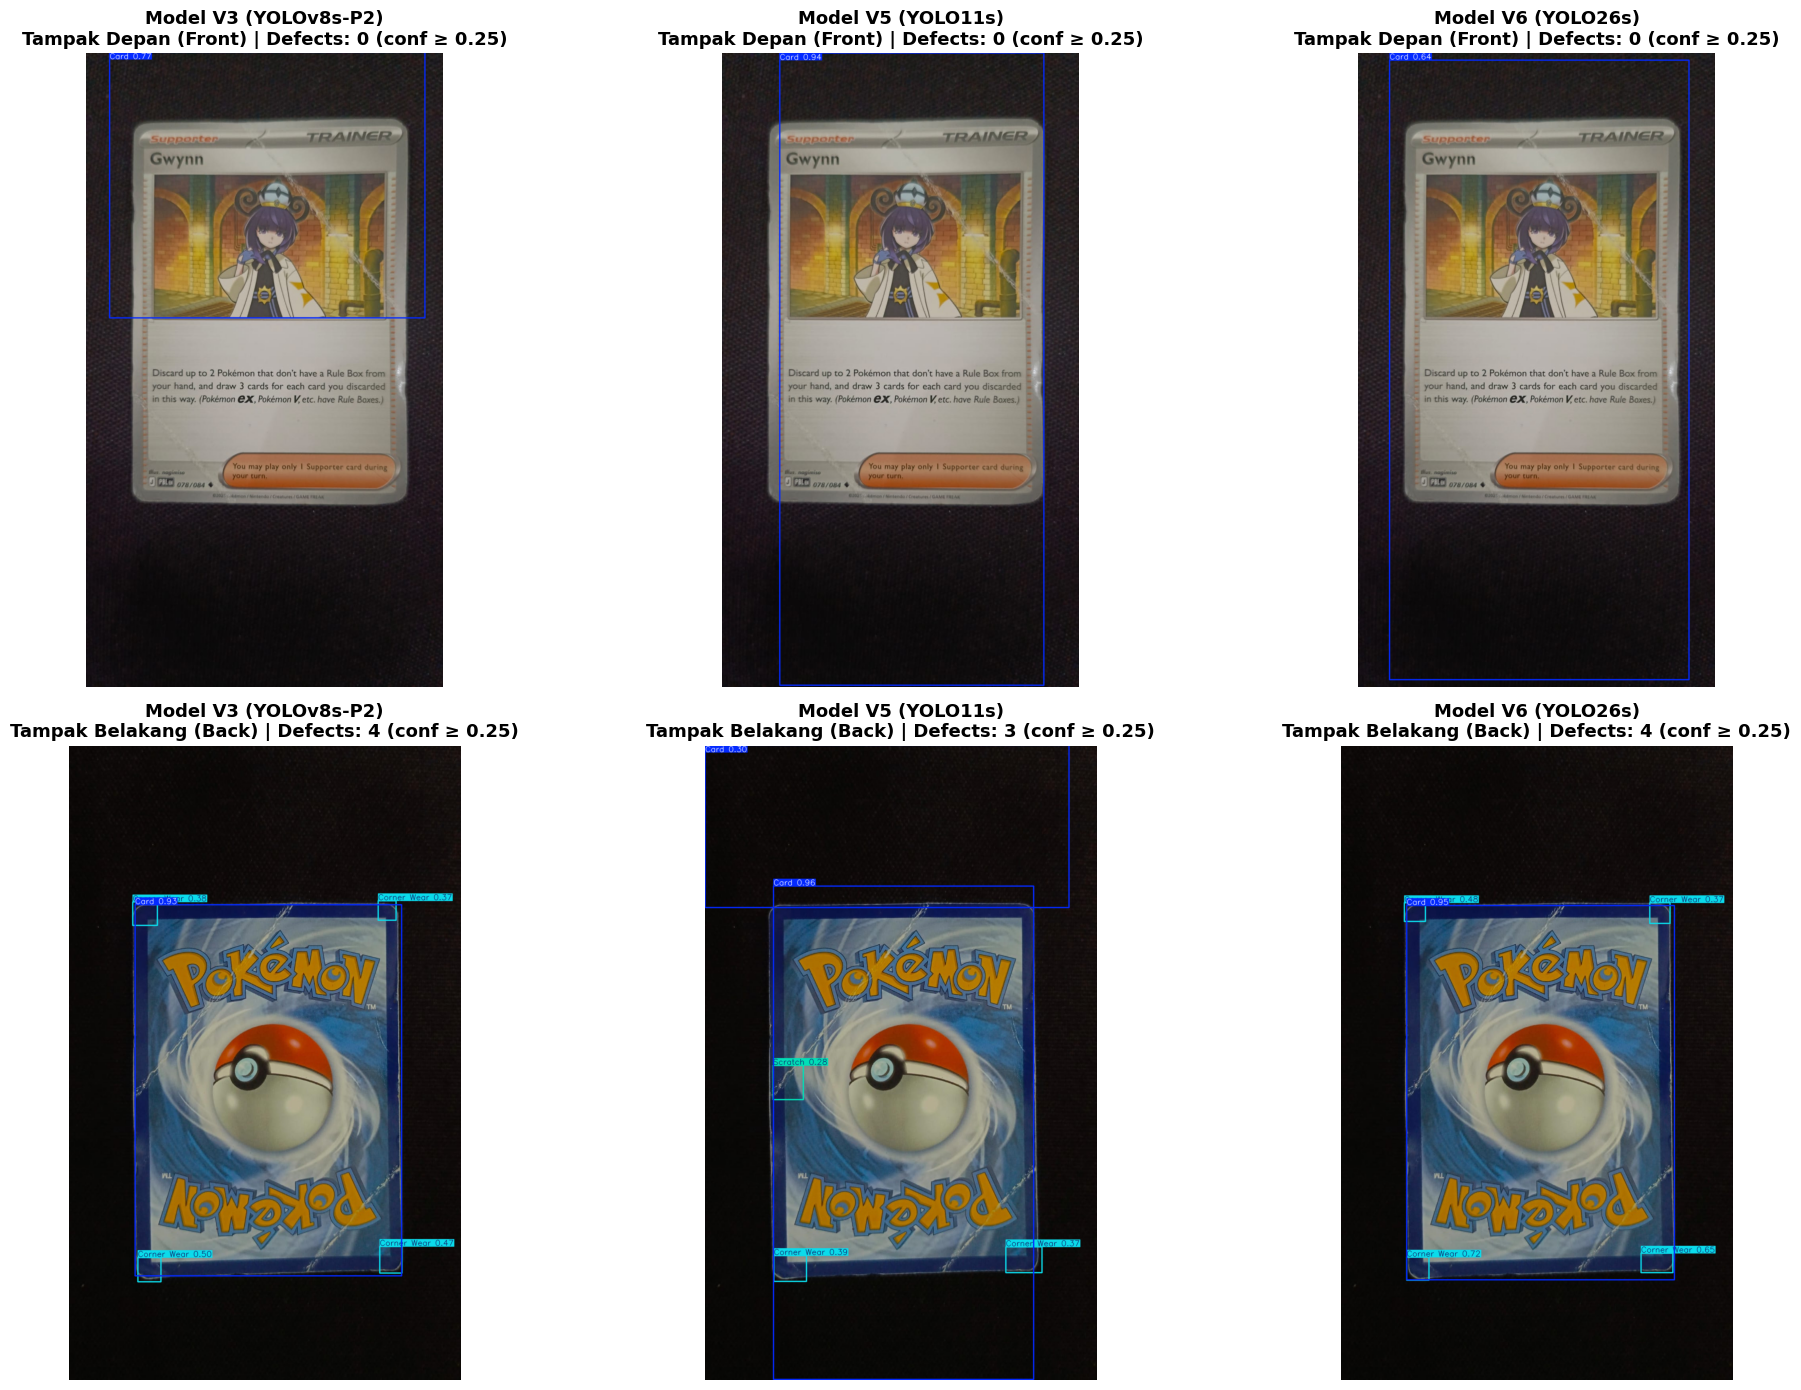


Gambar komparasi tersimpan di: /kaggle/working/perbandingan_foto_kartu_asli_v3_v5_v6.png


In [36]:
FRONT_IMG = find_kaggle_input("defect-card-front.jpeg")
BACK_IMG  = find_kaggle_input("defect-card-back.jpeg")

test_cards = [
    ("Tampak Depan (Front)", FRONT_IMG),
    ("Tampak Belakang (Back)", BACK_IMG),
]

models_to_compare = [
    ("Model V3 (YOLOv8s-P2)", model_v3, 640),
    ("Model V5 (YOLO11s)",    model_v5, 800),
    ("Model V6 (YOLO26s)",    model_v6, 800),
]

CONF_THRESH = 0.25

fig, axes = plt.subplots(len(test_cards), len(models_to_compare), figsize=(21, 14))

for row_idx, (side_title, img_path) in enumerate(test_cards):
    print("\n" + "=" * 70)
    print(f"FOTO KARTU ASLI: {side_title.upper()} ({os.path.basename(img_path)})")
    print("=" * 70)

    for col_idx, (model_label, mdl, infer_sz) in enumerate(models_to_compare):
        res = mdl.predict(source=img_path, conf=CONF_THRESH, imgsz=infer_sz, verbose=False)[0]

        # Plot bounding box ke gambar
        plotted_bgr = res.plot(line_width=2)
        plotted_rgb = cv2.cvtColor(plotted_bgr, cv2.COLOR_BGR2RGB)

        ax = axes[row_idx, col_idx]
        ax.imshow(plotted_rgb)
        ax.axis("off")

        # Hitung jumlah defect (selain kelas 'Card')
        defect_boxes = [
            b for b in res.boxes
            if mdl.names[int(b.cls[0].item())] != "Card"
        ]
        ax.set_title(
            f"{model_label}\n{side_title} | Defects: {len(defect_boxes)} (conf ≥ {CONF_THRESH})",
            fontsize=13,
            fontweight="bold"
        )

        # Log teks detail per model
        print(f"\n  [{model_label}]")
        if len(res.boxes) == 0:
            print("    - Tidak ada objek terdeteksi")
        else:
            for box in res.boxes:
                cls_name = mdl.names[int(box.cls[0].item())]
                conf_val = box.conf[0].item()
                print(f"    - {cls_name:<14} : {conf_val * 100:5.1f}%")

plt.tight_layout()
plt.savefig("/kaggle/working/perbandingan_foto_kartu_asli_v3_v5_v6.png", dpi=150, bbox_inches="tight")
plt.show()
print("\nGambar komparasi tersimpan di: /kaggle/working/perbandingan_foto_kartu_asli_v3_v5_v6.png")


[PIPELINE PRODUKSI: AUTO-CROP + CLAHE + NMS] TAMPAK DEPAN (FRONT)

  [Model V3 (YOLOv8s-P2)] -> Total Defect: 0
    - Card           :  81.2%

  [Model V5 (YOLO11s)] -> Total Defect: 0
    - Card           :  94.5%

  [Model V6 (YOLO26s)] -> Total Defect: 0
    - Card           :  94.6%

[PIPELINE PRODUKSI: AUTO-CROP + CLAHE + NMS] TAMPAK BELAKANG (BACK)

  [Model V3 (YOLOv8s-P2)] -> Total Defect: 4
    - Card           :  93.3%
    - Corner Wear    :  62.3%
    - Corner Wear    :  37.8%
    - Corner Wear    :  36.7%
    - Corner Wear    :  35.7%

  [Model V5 (YOLO11s)] -> Total Defect: 4
    - Card           :  94.1%
    - Corner Wear    :  35.5%
    - Corner Wear    :  27.9%
    - Corner Wear    :  24.6%
    - Scratch        :  26.6%

  [Model V6 (YOLO26s)] -> Total Defect: 5
    - Card           :  94.8%
    - Corner Wear    :  72.5%
    - Corner Wear    :  34.5%
    - Corner Wear    :  32.3%
    - Edge Wear      :  23.0%
    - Edge Wear      :  22.2%


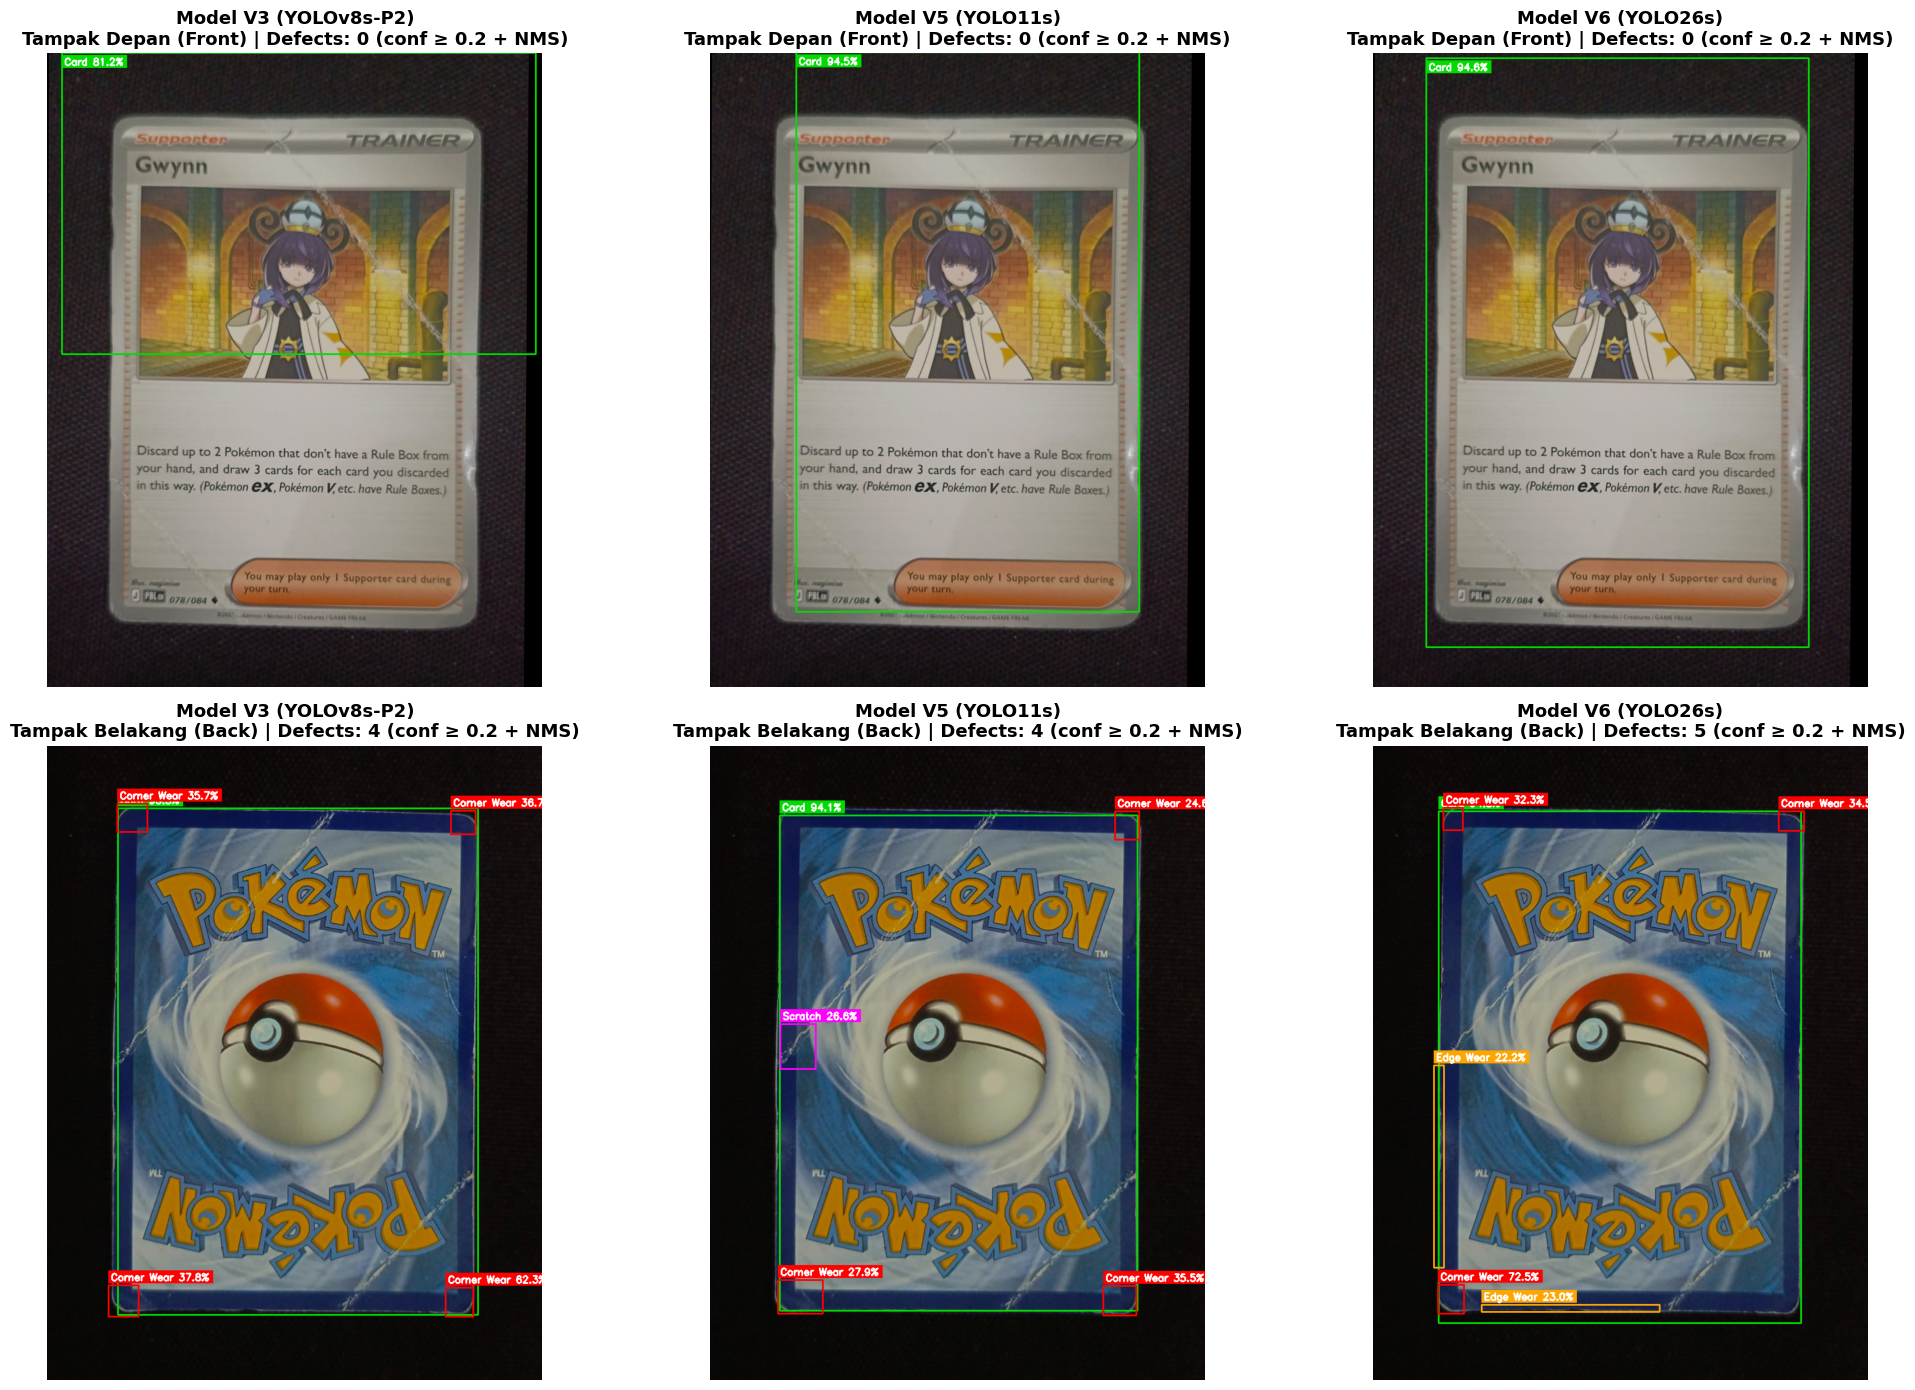

In [37]:
# [CODE CELL 6B — Uji Foto Kartu Asli dengan Pipeline Produksi Regokemon: Auto-Crop + CLAHE + Custom NMS]
from collections import defaultdict

CARD_ASPECT_RATIO = 63.0 / 88.0
CARD_OUT_SIZE = (600, 837)
LOW_THRESH_PROD = 0.20
IOU_NMS_PROD = 0.40

def _order_points(pts):
    pts = pts.reshape(4, 2).astype("float32")
    rect = np.zeros((4, 2), dtype="float32")
    s = pts.sum(axis=1)
    rect[0], rect[2] = pts[np.argmin(s)], pts[np.argmax(s)]
    diff = np.diff(pts, axis=1)
    rect[1], rect[3] = pts[np.argmin(diff)], pts[np.argmax(diff)]
    return rect

def _aspect_ok(rect, tol=0.22):
    (tl, tr, br, bl) = rect
    w = (np.linalg.norm(tr - tl) + np.linalg.norm(br - bl)) / 2.0
    h = (np.linalg.norm(bl - tl) + np.linalg.norm(br - tr)) / 2.0
    if h == 0:
        return None
    ratio = w / h
    if abs(ratio - CARD_ASPECT_RATIO) / CARD_ASPECT_RATIO < tol:
        return "portrait"
    if abs(ratio - (1.0 / CARD_ASPECT_RATIO)) / (1.0 / CARD_ASPECT_RATIO) < tol:
        return "landscape"
    return None

def _find_best_card_contour(binary_mask, w_img, h_img):
    frame_area = h_img * w_img
    contours, _ = cv2.findContours(binary_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    candidates = []
    for c in contours:
        hull = cv2.convexHull(c)
        eff_area = max(cv2.contourArea(c), cv2.contourArea(hull))
        if not (0.20 * frame_area <= eff_area <= 0.95 * frame_area):
            continue
        candidates.append((eff_area, c, hull))
    candidates.sort(key=lambda t: t[0], reverse=True)

    best = None
    for eff_area, c, hull in candidates[:5]:
        peri = cv2.arcLength(c, True)
        approx = cv2.approxPolyDP(c, 0.02 * peri, True)
        rect = _order_points(approx) if (len(approx) == 4 and cv2.isContourConvex(approx)) else None
        if rect is None:
            hull_peri = cv2.arcLength(hull, True)
            for eps in (0.02, 0.03, 0.05, 0.08):
                ha = cv2.approxPolyDP(hull, eps * hull_peri, True)
                if len(ha) == 4 and cv2.isContourConvex(ha):
                    rect = _order_points(ha)
                    break
        if rect is None:
            min_rect = cv2.minAreaRect(hull)
            rw, rh = min_rect[1]
            if rw * rh == 0 or (eff_area / (rw * rh)) < 0.70:
                continue
            rect = _order_points(cv2.boxPoints(min_rect))
        orient = _aspect_ok(rect)
        if orient and (best is None or eff_area > best[0]):
            best = (eff_area, rect, orient)
    return best

def preprocess_regokemon_pipeline(image_path, fallback_model):
    """Porting langsung dari auto_detect_card() + CLAHE di image_card_condition_test.py"""
    img = cv2.imread(image_path)
    h_img, w_img = img.shape[:2]
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    edge_strip = np.concatenate([gray[:15, :].ravel(), gray[-15:, :].ravel(), gray[:, :15].ravel(), gray[:, -15:].ravel()])
    is_bright_bg = np.mean(edge_strip) >= 100

    smooth = cv2.bilateralFilter(gray, 9, 60, 60)
    edges = cv2.Canny(cv2.createCLAHE(2.0, (8, 8)).apply(smooth), 30, 100)
    edges_closed = cv2.morphologyEx(edges, cv2.MORPH_CLOSE, np.ones((21, 21), np.uint8), iterations=2)

    if not is_bright_bg:
        blurred = cv2.GaussianBlur(gray, (51, 51), 0)
        _, bin_norm = cv2.threshold(blurred, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
        bin_norm = cv2.morphologyEx(bin_norm, cv2.MORPH_CLOSE, np.ones((25, 25), np.uint8), iterations=3)
        bin_norm = cv2.morphologyEx(bin_norm, cv2.MORPH_OPEN, np.ones((15, 15), np.uint8), iterations=2)
        masks = [bin_norm, edges_closed]
    else:
        blurred_l = cv2.GaussianBlur(gray, (15, 15), 0)
        _, bin_inv = cv2.threshold(blurred_l, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
        bin_inv = cv2.morphologyEx(bin_inv, cv2.MORPH_CLOSE, np.ones((15, 15), np.uint8), iterations=2)
        masks = [edges_closed, bin_inv]

    best = None
    for m in masks:
        cand = _find_best_card_contour(m, w_img, h_img)
        if cand is not None and cand[0] >= 0.35 * (w_img * h_img):
            best = cand
            break
        if cand is not None and (best is None or cand[0] > best[0]):
            best = cand

    if best is None:
        res_fb = fallback_model.predict(img, conf=0.15, verbose=False)[0]
        c_boxes = [(float(b.conf[0]), b.xyxy[0].tolist()) for b in res_fb.boxes if res_fb.names[int(b.cls[0])] == "Card"]
        if c_boxes:
            c_boxes.sort(key=lambda x: x[0], reverse=True)
            _, (x1, y1, x2, y2) = c_boxes[0]
            rect = _order_points(np.array([[x1, y1], [x2, y1], [x2, y2], [x1, y2]], dtype="float32"))
            orient = "landscape" if (x2 - x1) > (y2 - y1) else "portrait"
            best = ((x2 - x1) * (y2 - y1), rect, orient)

    if best is None:
        return img, img

    _, rect, orient = best
    width, height = CARD_OUT_SIZE
    margin = 120
    out_w, out_h = width + 2 * margin, height + 2 * margin
    if orient == "landscape":
        dst = np.array([[margin, margin], [margin + height - 1, margin],
                        [margin + height - 1, margin + width - 1], [margin, margin + width - 1]], dtype="float32")
        warped = cv2.warpPerspective(img, cv2.getPerspectiveTransform(rect, dst), (out_h, out_w), flags=cv2.INTER_CUBIC)
        warped = cv2.rotate(warped, cv2.ROTATE_90_CLOCKWISE)
    else:
        dst = np.array([[margin, margin], [margin + width - 1, margin],
                        [margin + width - 1, margin + height - 1], [margin, margin + height - 1]], dtype="float32")
        warped = cv2.warpPerspective(img, cv2.getPerspectiveTransform(rect, dst), (out_w, out_h), flags=cv2.INTER_CUBIC)

    # Sharpness check + Unsharp Mask + LAB CLAHE (persis image_card_condition_test.py)
    work = warped.copy()
    sharp = cv2.Laplacian(cv2.cvtColor(warped, cv2.COLOR_BGR2GRAY), cv2.CV_64F).var()
    if sharp < 70.0:
        blur_usm = cv2.GaussianBlur(work, (0, 0), 2.0)
        work = cv2.addWeighted(work, 1.5, blur_usm, -0.5, 0)

    lab = cv2.cvtColor(work, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    enhanced_bgr = cv2.cvtColor(cv2.merge((cv2.createCLAHE(2.5, (8, 8)).apply(l), a, b)), cv2.COLOR_LAB2BGR)
    return warped, enhanced_bgr

def custom_nms_and_top1_card(boxes, names, iou_thresh=0.40):
    """Terapkan NMS per kelas + hanya simpan 1 kotak 'Card' terbaik."""
    dets = []
    for b in boxes:
        x1, y1, x2, y2 = b.xyxy[0].tolist()
        dets.append({
            "class": names[int(b.cls[0].item())],
            "conf": float(b.conf[0].item()),
            "box": (x1, y1, x2, y2),
        })

    def calc_iou(b1, b2):
        ix1, iy1 = max(b1[0], b2[0]), max(b1[1], b2[1])
        ix2, iy2 = min(b1[2], b2[2]), min(b1[3], b2[3])
        inter = max(0.0, ix2 - ix1) * max(0.0, iy2 - iy1)
        area1 = (b1[2] - b1[0]) * (b1[3] - b1[1])
        area2 = (b2[2] - b2[0]) * (b2[3] - b2[1])
        union = area1 + area2 - inter
        return inter / union if union > 0 else 0.0

    by_cls = defaultdict(list)
    for d in dets:
        by_cls[d["class"]].append(d)

    kept = []
    for cls_name, cls_dets in by_cls.items():
        cls_dets.sort(key=lambda d: d["conf"], reverse=True)
        if cls_name == "Card":
            kept.append(cls_dets[0])  # Hanya ambil Top-1 Card seperti di aplikasi
            continue
        suppressed = set()
        for i, a in enumerate(cls_dets):
            if i in suppressed:
                continue
            kept.append(a)
            for j in range(i + 1, len(cls_dets)):
                if calc_iou(a["box"], cls_dets[j]["box"]) > iou_thresh:
                    suppressed.add(j)
    return kept

COLORS_BGR = {
    "Card":        (0, 220, 0),
    "Corner Wear": (0, 0, 255),
    "Edge Wear":   (0, 165, 255),
    "Scratch":     (255, 0, 255),
}

fig, axes = plt.subplots(len(test_cards), len(models_to_compare), figsize=(21, 14))

for row_idx, (side_title, img_path) in enumerate(test_cards):
    display_card, clahe_card = preprocess_regokemon_pipeline(img_path, fallback_model=model_v6)
    print("\n" + "=" * 74)
    print(f"[PIPELINE PRODUKSI: AUTO-CROP + CLAHE + NMS] {side_title.upper()}")
    print("=" * 74)

    for col_idx, (model_label, mdl, infer_sz) in enumerate(models_to_compare):
        res = mdl.predict(source=clahe_card, conf=LOW_THRESH_PROD, imgsz=infer_sz, verbose=False)[0]
        filtered = custom_nms_and_top1_card(res.boxes, mdl.names, iou_thresh=IOU_NMS_PROD)

        canvas = display_card.copy()
        defects_only = [d for d in filtered if d["class"] != "Card"]

        for d in filtered:
            x1, y1, x2, y2 = map(int, d["box"])
            color = COLORS_BGR.get(d["class"], (255, 255, 0))
            cv2.rectangle(canvas, (x1, y1), (x2, y2), color, 2)
            lbl = f"{d['class']} {d['conf']*100:.1f}%"
            (tw, th), _ = cv2.getTextSize(lbl, cv2.FONT_HERSHEY_SIMPLEX, 0.55, 2)
            ty = y1 - 8 if y1 - th - 8 > 0 else y1 + th + 8
            cv2.rectangle(canvas, (x1, ty - th - 4), (x1 + tw + 8, ty + 4), color, -1)
            cv2.putText(canvas, lbl, (x1 + 4, ty), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 255, 255), 2)

        ax = axes[row_idx, col_idx]
        ax.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
        ax.axis("off")
        ax.set_title(
            f"{model_label}\n{side_title} | Defects: {len(defects_only)} (conf ≥ {LOW_THRESH_PROD} + NMS)",
            fontsize=13, fontweight="bold"
        )

        print(f"\n  [{model_label}] -> Total Defect: {len(defects_only)}")
        for d in filtered:
            print(f"    - {d['class']:<14} : {d['conf']*100:5.1f}%")

plt.tight_layout()
plt.savefig("/kaggle/working/perbandingan_pipeline_produksi_v3_v5_v6.png", dpi=150, bbox_inches="tight")
plt.show()